# Field Animation Examples

This notebook demonstrates the four animation backends for visualizing spatial fields over time:

1. **Napari** - GPU-accelerated interactive viewer (large-scale exploration)
2. **Video** - Parallel MP4 export (publications, presentations)
3. **HTML** - Standalone interactive files (sharing, remote viewing)
4. **Jupyter Widget** - Notebook integration (quick exploration)

**Estimated time**: 15-20 minutes

**Prerequisites**: [08_spike_field_basics.ipynb](08_spike_field_basics.ipynb)

## Learning Objectives

By the end of this notebook, you will be able to:

- Animate spatial fields over time using the `animate_fields()` method
- Choose the appropriate backend for different use cases
- Export videos for publications with parallel rendering
- Create shareable HTML players with instant scrubbing
- Handle large-scale datasets (900K+ frames) with memory-mapped arrays
- Subsample high-frequency neural data for video export

## Prerequisites

**Optional dependencies** (install as needed):

```bash
# For Napari backend
pip install 'napari[all]>=0.4.18'

# For Jupyter widget backend
pip install 'ipywidgets>=8.0'

# For video backend (system dependency)
# macOS: brew install ffmpeg
# Ubuntu: sudo apt install ffmpeg
# Windows: https://ffmpeg.org/download.html
```

Note: HTML backend requires no additional dependencies.

The default run creates static previews and temporary demo artifacts. Desktop
viewers and expensive final exports require an explicit opt-in below, even
when their packages are installed. Re-run cells after changing a flag.


In [1]:
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import Point

from neurospatial import Environment
from neurospatial.animation import subsample_frames
from neurospatial.animation.backends.video_backend import check_ffmpeg_available

RUN_NAPARI = False
RUN_VIDEO_EXPORT = False
RUN_WIDGET = False  # optional notebook controls, also disabled for batch execution

# Set random seed for reproducibility
np.random.seed(42)

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(12, 8))

# Determine output directory (works whether running as script or notebook)
output_dir = Path(tempfile.mkdtemp(prefix="neurospatial-example-16-"))
print(f"Output directory: {output_dir}")

Output directory: /var/folders/5c/vh9h5cyd3p71_g3cw0zjnc_m0000gn/T/neurospatial-example-16-fa7get54


## Setup: Create Environment and Simulate Remapping

We'll simulate place field remapping across 30 trials, where the field:
- Starts with activity at location A (trials 1-15)
- Undergoes remapping to location B (trials 16-30)
- Demonstrates context-dependent spatial coding

These prescribed synthetic maps illustrate display behavior; they are not
rate estimates from spikes or evidence of a remapping mechanism. Values are
arbitrary units, and one second per trial is an assigned presentation clock.
Related experimental phenomena include:
- Environmental context changes
- Learning new reward locations
- Hippocampal remapping events

In [2]:
print("Creating circular arena environment...")

# Create a circular arena (50 cm radius, 100 cm diameter)
# This is a common neuroscience experimental setup
center = Point(50, 50)
radius = 50.0
circle = center.buffer(radius)

env = Environment.from_polygon(polygon=circle, bin_size=2.5, name="CircularArena")
env.units = "cm"
env.frame = "open_field"

print(f"Environment: Circular arena (radius={radius:.0f} cm)")
print(f"  {env.n_bins} bins, {env.n_dims}D")

Creating circular arena environment...
Environment: Circular arena (radius=50 cm)
  1264 bins, 2D


In [3]:
# Simulate place field remapping across trials
print("\nSimulating place field remapping...")

n_trials = 30
remap_trial = 15  # Field remaps halfway through

# Location A: Upper-right quadrant (60, 65) cm
location_a = np.array([60.0, 65.0])
bin_a = env.bin_at(location_a.reshape(1, -1))[0]

# Location B: Lower-left quadrant (40, 35) cm
location_b = np.array([40.0, 35.0])
bin_b = env.bin_at(location_b.reshape(1, -1))[0]

print(
    f"Location A (trials 1-{remap_trial}): bin {bin_a} at [{location_a[0]:.1f}, {location_a[1]:.1f}] cm"
)
print(
    f"Location B (trials {remap_trial + 1}-{n_trials}): bin {bin_b} at [{location_b[0]:.1f}, {location_b[1]:.1f}] cm"
)

fields = []
for trial in range(n_trials):
    # Determine which location is active
    if trial < remap_trial:
        # Before remapping: field at location A
        active_bin = bin_a
        field_strength = 1.0  # Full strength at A
    else:
        # After remapping: field at location B
        active_bin = bin_b
        # Gradual emergence at new location
        field_strength = min(1.0, (trial - remap_trial + 1) / 5)

    # Compute distances from active location
    distances = env.distance_to([active_bin])

    # Gaussian place field with consistent width
    sigma = 8.0  # cm (typical place field size)
    field = field_strength * np.exp(-(distances**2) / (2 * sigma**2))

    # Add realistic noise
    noise = np.random.randn(env.n_bins) * 0.15
    field = field + noise
    field = np.maximum(field, 0)  # Non-negative firing rates

    fields.append(field)

print(f"Generated {len(fields)} trial fields (remapping at trial {remap_trial})")

# Create frame_times for animation (1 second per trial)
# This defines the temporal structure - speed parameter controls playback rate
trial_duration = 1.0  # seconds per trial
frame_times = np.arange(n_trials) * trial_duration
print(
    f"Frame times: {frame_times[0]:.1f}s to {frame_times[-1]:.1f}s ({trial_duration}s/trial)"
)


Simulating place field remapping...
Location A (trials 1-15): bin 817 at [60.0, 65.0] cm
Location B (trials 16-30): bin 486 at [40.0, 35.0] cm


Generated 30 trial fields (remapping at trial 15)
Frame times: 0.0s to 29.0s (1.0s/trial)


A static preview runs with the core dependencies. The shared color scale keeps
prescribed changes in amplitude visible across the two example frames.

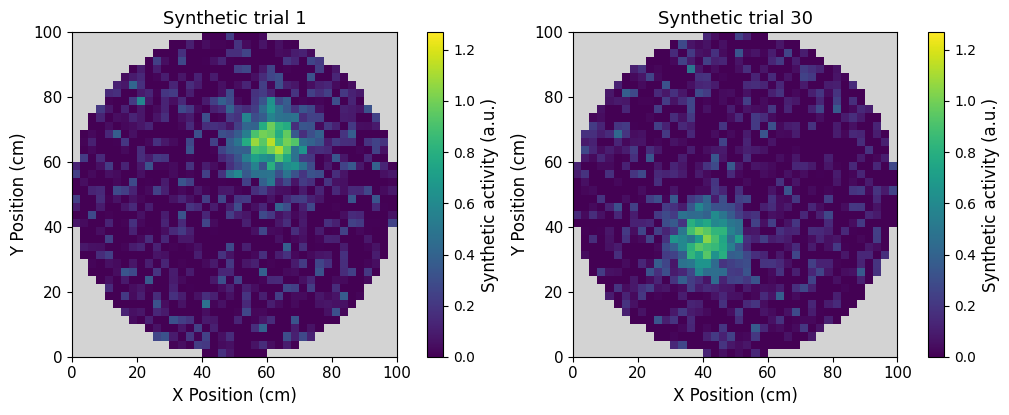

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, index in zip(axes, [0, n_trials - 1], strict=True):
    env.plot_field(
        fields[index],
        ax=ax,
        vmin=0,
        vmax=float(np.max(fields)),
        colorbar_label="Synthetic activity (a.u.)",
    )
    ax.set_title(f"Synthetic trial {index + 1}")
plt.show()

## Example 1: Interactive Napari Viewer

**Best for**: Large datasets, exploration, real-time interaction

**Features**:
- GPU-accelerated rendering
- Instant seeking through frames
- Memory-efficient lazy loading
- Suitable for 100K+ frames

**Installation**: `pip install 'napari[all]>=0.4.18'`

In [5]:
if RUN_NAPARI:
    try:
        import napari
        from IPython import get_ipython

        print("Launching Napari viewer...")
        print("")
        print("ENHANCED PLAYBACK CONTROLS:")
        print("")
        print("Built-in Controls (bottom-left):")
        print("  ▶ Play button - Start/stop animation")
        print("  ━ Time slider - Scrub through frames with instant seeking")
        print("  Frame counter - Shows current frame (e.g., '1/30')")
        print("")
        print("Enhanced Widget (left sidebar - auto-added):")
        print("  ⏯ Large Play/Pause button - Toggle animation (synced with spacebar)")
        print("  📊 Speed slider - Control playback relative to real-time")
        print("  📋 Frame counter - 'Frame: 15 / 30' with trial label")
        print("  ✓ Updates in real-time during playback")
        print("")
        print("Keyboard Shortcuts:")
        print("  Spacebar - Play/pause (toggle)")
        print("  ← → Arrow keys - Step through frames")
        print("")
        print("Memory Efficiency:")
        print("  - Lazy loading with LRU caching (1000 frame cache)")
        print("  - Chunked caching for >10K frames (100 frames/chunk)")
        print("  - On-demand seeking; performance depends on data size and hardware")
        print("  - GPU-accelerated rendering")
        print("")

        viewer = env.animate_fields(
            fields,
            backend="napari",
            frame_times=frame_times,
            speed=10.0,  # 10x real-time (1 trial/second → 10 trials/second)
            frame_labels=[f"Trial {i + 1}" for i in range(n_trials)],
            title="Place Field Remapping",
            scale_bar=True,  # Shows scale bar with units (env.units = "cm")
        )

        print("✓ Napari viewer opened")

        # Only call napari.run() when running as a script (not in Jupyter)
        # In Jupyter, the viewer stays open without blocking execution
        if get_ipython() is None:
            print("  (Running as script - window will block until closed)")
            napari.run()
        else:
            print("  (Running in Jupyter - window stays open, execution continues)")

    except ImportError:
        print("⊗ Napari not available. Install with: pip install 'napari[all]>=0.4.18'")
else:
    print("Optional viewer skipped; set RUN_NAPARI=True to enable it.")

Optional viewer skipped; set RUN_NAPARI=True to enable it.


## Example 1b: Multi-Field Viewer (Comparing Multiple Neurons)

**Best for**: Comparing spatial fields across multiple neurons/conditions

**New Features**:
- Side-by-side comparison of multiple field sequences
- Synchronized playback across all layers
- Global color scale for fair comparison
- Layout options: horizontal, vertical, or grid
- Custom layer names for clarity

**Use cases**:
- Comparing place fields across neuron ensembles
- Visualizing learning across multiple trials
- Side-by-side condition comparison (pre/post manipulation)

In [6]:
if RUN_NAPARI:
    try:
        import napari
        from IPython import get_ipython

        print("Creating multi-field comparison...")
        print("")
        print("Simulating 3 neurons with different spatial tuning:")

        # Create 3 different neurons with distinct spatial patterns
        # Neuron A: Maintains stable field at location A
        # Neuron B: Remaps from A to B (like our original example)
        # Neuron C: Has field at location B throughout

        fields_neuron_a = []  # Stable at location A
        fields_neuron_b = []  # Remaps from A to B
        fields_neuron_c = []  # Stable at location B

        for trial in range(n_trials):
            # Neuron A: Stable field at location A
            distances_a = env.distance_to([bin_a])
            field_a = np.exp(-(distances_a**2) / (2 * 8.0**2))
            field_a = field_a + np.random.randn(env.n_bins) * 0.15
            field_a = np.maximum(field_a, 0)
            fields_neuron_a.append(field_a)

            # Neuron B: Remapping neuron (from earlier example)
            # This is the same remapping pattern as before
            if trial < remap_trial:
                active_bin = bin_a
                field_strength = 1.0
            else:
                active_bin = bin_b
                field_strength = min(1.0, (trial - remap_trial + 1) / 5)

            distances_b = env.distance_to([active_bin])
            field_b = field_strength * np.exp(-(distances_b**2) / (2 * 8.0**2))
            field_b = field_b + np.random.randn(env.n_bins) * 0.15
            field_b = np.maximum(field_b, 0)
            fields_neuron_b.append(field_b)

            # Neuron C: Stable field at location B
            distances_c = env.distance_to([bin_b])
            field_c = np.exp(-(distances_c**2) / (2 * 8.0**2))
            field_c = field_c + np.random.randn(env.n_bins) * 0.15
            field_c = np.maximum(field_c, 0)
            fields_neuron_c.append(field_c)

        print("  Neuron A: Stable field at location A")
        print("  Neuron B: Remaps from A → B at trial 15")
        print("  Neuron C: Stable field at location B")
        print("")

        # Launch multi-field viewer
        print("Launching multi-field Napari viewer...")
        print("")
        print("LAYOUT: Horizontal (side-by-side comparison)")
        print("  - All fields share same color scale (fair comparison)")
        print("  - Synchronized playback across layers")
        print("  - Custom layer names for clarity")
        print("")
        print("PLAYBACK CONTROLS (same as single-field viewer):")
        print("  Bottom-left: ▶ Play button, time slider")
        print("  Keyboard: Spacebar (play/pause), ← → (step frames)")
        print("  Left sidebar: 📊 'Playback Speed' widget")
        print("")

        viewer = env.animate_fields(
            fields=[
                fields_neuron_a,
                fields_neuron_b,
                fields_neuron_c,
            ],  # List of sequences
            backend="napari",
            layout="horizontal",  # Side-by-side arrangement
            layer_names=[
                "Neuron A (Stable A)",
                "Neuron B (Remap A→B)",
                "Neuron C (Stable B)",
            ],
            frame_times=frame_times,
            speed=10.0,  # 10x real-time
            frame_labels=[f"Trial {i + 1}" for i in range(n_trials)],
            title="Multi-Neuron Comparison",
            scale_bar=True,  # Shows scale bar with units (env.units = "cm")
        )

        print("✓ Multi-field viewer opened!")
        print("")
        print("TIP: Watch how Neuron B remaps while A and C stay stable")
        print(
            "TIP: Try different layouts - change 'horizontal' to 'vertical' or 'grid'"
        )

        # Only call napari.run() when running as a script (not in Jupyter)
        if get_ipython() is None:
            print("  (Running as script - window will block until closed)")
            napari.run()
        else:
            print("  (Running in Jupyter - window stays open, execution continues)")

    except ImportError:
        print("⊗ Napari not available. Install with: pip install 'napari[all]>=0.4.18'")
else:
    print("Optional viewer skipped; set RUN_NAPARI=True to enable it.")

Optional viewer skipped; set RUN_NAPARI=True to enable it.


## Example 2: Video Export (MP4)

**Best for**: Publications, presentations, high-quality renders

**Features**:
- Parallel rendering for speed
- High-quality output
- Multiple codec options (h264, h265, vp9, mpeg4)
- Dry-run mode for time/size estimation

**Installation**: System dependency (ffmpeg)
- macOS: `brew install ffmpeg`
- Ubuntu: `sudo apt install ffmpeg`
- Windows: Download from https://ffmpeg.org/download.html

In [7]:
if RUN_VIDEO_EXPORT and check_ffmpeg_available():
    print("Exporting video with parallel rendering...")

    output_path = env.animate_fields(
        fields,
        backend="video",
        save_path=output_dir / "16_place_field_remapping.mp4",
        frame_times=frame_times,
        speed=5.0,  # 5x real-time
        cmap="hot",
        frame_labels=[f"Trial {i + 1}" for i in range(n_trials)],
        n_workers=1,  # Script-safe serial rendering
        dpi=100,
    )
    print(f"✓ Video saved to {output_path}")

else:
    print(
        "⊗ Video export disabled by default or ffmpeg unavailable; set RUN_VIDEO_EXPORT=True to enable."
    )
    print("  Install: brew install ffmpeg (macOS) or apt install ffmpeg (Linux)")

⊗ Video export disabled by default or ffmpeg unavailable; set RUN_VIDEO_EXPORT=True to enable.
  Install: brew install ffmpeg (macOS) or apt install ffmpeg (Linux)


## Example 3: Standalone HTML Player

**Best for**: Sharing, remote viewing, no dependencies

**Features**:
- Single self-contained file
- Works offline in any browser
- Instant scrubbing with slider
- Play/pause controls
- Keyboard shortcuts (space, arrows)

**Installation**: No dependencies required

In [8]:
print("Generating HTML player...")

html_path = env.animate_fields(
    fields,
    backend="html",
    save_path=output_dir / "16_place_field_remapping.html",
    frame_times=frame_times,
    speed=10.0,  # 10x real-time
    cmap="viridis",
    frame_labels=[f"Trial {i + 1}" for i in range(n_trials)],
)

print(f"✓ HTML player saved to {html_path}")
print("  - Open in any web browser")
print("  - Instant scrubbing with slider")
print("  - Shareable (single file)")
print("  - Keyboard shortcuts: space = play/pause, arrows = step")

Generating HTML player...


Encoding frames:   0%|          | 0/30 [00:00<?, ?it/s]

Encoding frames:  13%|█▎        | 4/30 [00:00<00:00, 38.81it/s]

Encoding frames:  30%|███       | 9/30 [00:00<00:00, 44.84it/s]

Encoding frames:  50%|█████     | 15/30 [00:00<00:00, 47.15it/s]

Encoding frames:  73%|███████▎  | 22/30 [00:00<00:00, 52.45it/s]

Encoding frames:  93%|█████████▎| 28/30 [00:00<00:00, 53.88it/s]

Encoding frames: 100%|██████████| 30/30 [00:00<00:00, 51.31it/s]

✓ HTML player saved to /var/folders/5c/vh9h5cyd3p71_g3cw0zjnc_m0000gn/T/neurospatial-example-16-fa7get54/16_place_field_remapping.html
  - Open in any web browser
  - Instant scrubbing with slider
  - Shareable (single file)
  - Keyboard shortcuts: space = play/pause, arrows = step


## Example 4: Jupyter Widget

**Best for**: Quick checks in notebooks, interactive exploration

**Features**:
- Integrated controls in notebook
- Play/pause button
- Slider for frame selection
- Automatic display in output cell

**Installation**: `pip install 'ipywidgets>=8.0'`

In [9]:
if RUN_WIDGET:
    try:
        from IPython import get_ipython

        if get_ipython() is not None:
            print("Creating Jupyter widget...")

            widget = env.animate_fields(
                fields,
                backend="widget",
                frame_times=frame_times,
                speed=10.0,  # 10x real-time
                frame_labels=[f"Trial {i + 1}" for i in range(n_trials)],
            )

            print("✓ Widget created (displayed above)")
        else:
            print("⊗ Not in Jupyter notebook - widget skipped")
    except ImportError:
        print("⊗ IPython not available - widget skipped")
else:
    print("Optional viewer skipped; set RUN_WIDGET=True to enable it.")

Optional viewer skipped; set RUN_WIDGET=True to enable it.


## Example 5: Large-Scale Session Pattern

**Best for**: Hour-long recordings at high sampling rates (e.g., 250 Hz)

**Key techniques**:
- Memory-mapped arrays (don't load all data into RAM)
- Napari for interactive exploration (lazy loading)
- Frame subsampling for video export
- Dry-run estimation before rendering

**This example demonstrates the pattern** for handling large sessions:
- Real sessions: 60K-900K frames (4 min - 1 hour at 250 Hz)
- Real file sizes: 300 MB - 4.5 GB
- Demo version: 1000 frames (~5 MB) to avoid filling your disk

The memmap pattern can support larger files, subject to disk capacity,
renderer/cache memory and acceptable latency. This default demo stays small.

In [10]:
print("=" * 80)
print("Example 5: Large-Scale Session Pattern")
print("=" * 80)

print("\nDemonstrating techniques for large datasets (60K-900K frames):")
print("  - Use memory-mapped data (don't load into RAM)")
print("  - Use Napari for exploration (lazy loading)")
print("  - Subsample for video export")
print("\nNote: Using 1000 frames (~5 MB) for demo; scales to hours of data")

Example 5: Large-Scale Session Pattern

Demonstrating techniques for large datasets (60K-900K frames):
  - Use memory-mapped data (don't load into RAM)
  - Use Napari for exploration (lazy loading)
  - Subsample for video export

Note: Using 1000 frames (~5 MB) for demo; scales to hours of data


### Step 1: Create Memory-Mapped Data File

In practice, this would be your neural recording data. We'll simulate it here for demonstration.

In [11]:
# Create memory-mapped data file (simulating neural recording)
print("\nCreating memory-mapped data file...")
# For demo purposes, use a small file (1000 frames ~5 MB)
# In practice, this would be 60K-900K frames for real sessions
n_frames_large = 1000  # Demo size (real: 60K-900K frames)

# Use temporary directory for demo (in practice, use your data directory)
tmpdir = Path(tempfile.mkdtemp(prefix="neurospatial_demo_"))
mmap_path = tmpdir / "large_session.dat"

fields_mmap = np.memmap(
    str(mmap_path),
    dtype="float32",
    mode="w+",  # Create new file
    shape=(n_frames_large, env.n_bins),
)

print("Populating with sample data (in practice, this is your recording)...")
print("  (Writing in chunks to avoid memory issues)")

# Populate with simulated data (in practice, this is your neural recording)
# For this example, we'll simulate a slowly drifting place field
initial_bin = env.n_bins // 2  # Start at center of environment

chunk_size = 100
for i in range(0, n_frames_large, chunk_size):
    # Simulate place field that drifts slowly over time
    chunk_end = min(i + chunk_size, n_frames_large)
    chunk_len = chunk_end - i

    # Move in physical coordinates; neighboring numeric bin IDs need not be
    # neighbors in space. One center per chunk is sufficient for this I/O demo.
    center_bin = env.bin_at(np.array([[40.0 + 20.0 * i / n_frames_large, 50.0]]))[0]

    distances = env.distance_to([center_bin])
    for j in range(chunk_len):
        fields_mmap[i + j] = np.maximum(
            0, np.exp(-distances / 15) + np.random.randn(env.n_bins) * 0.1
        )

fields_mmap.flush()

# Create frame_times for the large session (250 Hz sampling rate)
large_session_sample_rate = 250.0  # Hz
large_session_duration = n_frames_large / large_session_sample_rate
large_session_frame_times = np.arange(n_frames_large) / large_session_sample_rate

print(f"\n✓ Created memory-mapped dataset: {n_frames_large:,} frames")
print(f"  File size: {n_frames_large * env.n_bins * 4 / 1e9:.2f} GB")
print(
    f"  Duration: {large_session_duration:.1f}s at {large_session_sample_rate:.0f} Hz"
)
print(
    "  Memory mapping avoids an eager full-array copy; OS pages and render caches still use RAM."
)


Creating memory-mapped data file...
Populating with sample data (in practice, this is your recording)...
  (Writing in chunks to avoid memory issues)

✓ Created memory-mapped dataset: 1,000 frames
  File size: 0.01 GB
  Duration: 4.0s at 250 Hz
  Memory mapping avoids an eager full-array copy; OS pages and render caches still use RAM.


### Step 2: Interactive Exploration with Napari

Napari loads frames on-demand, making it efficient for exploring large datasets.

In [12]:
print("\nOption 1: Interactive exploration (Napari)")
print("  Napari loads frames on-demand - would handle 900K frames efficiently")

if RUN_NAPARI:
    try:
        # Import napari only if attempting to use it
        import napari
        from IPython import get_ipython

        print("")
        print("CHUNKED CACHING FOR LARGE DATASETS:")
        print(
            "  - Auto-enabled for >10K frames (this demo has 1000, but shows the pattern)"
        )
        print("  - Caches frames in chunks of 100 (not individual frames)")
        print("  - Pre-loads neighboring frames for smooth sequential playback")
        print("  - Reduces cache overhead: 900K frames → 9K chunks")
        print("  - LRU eviction: keeps recently accessed chunks in memory")
        print("  - Benefits:")
        print("    • 10x fewer cache entries (faster lookups)")
        print("    • Better sequential playback (pre-loaded neighbors)")
        print("    • Seeking performance depends on disk, cache and rendering settings")
        print("")
        print("PLAYBACK CONTROLS:")
        print("  Bottom-left: ▶ Play button, time slider")
        print("  Keyboard: Spacebar (play/pause), ← → (step frames)")
        print("  Left sidebar: 📊 'Playback Speed' widget")
        print("")

        viewer = env.animate_fields(
            fields_mmap,
            backend="napari",
            frame_times=large_session_frame_times,
            speed=1.0,  # Real-time playback
            title="Large Session Demo (1000 frames)",
            scale_bar=True,  # Shows scale bar with units (env.units = "cm")
            # cache_chunk_size=100,  # Auto-detected (default for >10K frames)
        )
        print("✓ Napari viewer opened!")
        print("  (Same technique works for 60K-900K frame sessions)")

        # Only call napari.run() when running as a script (not in Jupyter)
        if get_ipython() is None:
            print("  (Running as script - window will block until closed)")
            napari.run()
        else:
            print("  (Running in Jupyter - window stays open, execution continues)")

    except ImportError:
        print("⊗ Napari not available (install: pip install 'napari[all]>=0.4.18')")
else:
    print("Optional viewer skipped; set RUN_NAPARI=True to enable it.")


Option 1: Interactive exploration (Napari)
  Napari loads frames on-demand - would handle 900K frames efficiently
Optional viewer skipped; set RUN_NAPARI=True to enable it.


### Step 3: Export Subsampled Video

For video export, we need to subsample the high-frequency data to a manageable frame rate.

In [13]:
print("\nOption 2: Export subsampled video")
print("  For large sessions: 250 Hz → 30 fps requires subsampling")

# Subsample 250 Hz → 30 fps
# For 900K frames, this would produce 108K subsampled frames (1 hour video)
# For our 1000 frame demo, this produces ~120 frames
fields_subsampled = subsample_frames(fields_mmap, target_fps=30, source_fps=250)
subsampled_frame_times = subsample_frames(
    large_session_frame_times, target_fps=30, source_fps=250
)
assert len(subsampled_frame_times) == len(fields_subsampled)
print(
    f"  Subsampled: {len(fields_subsampled):,} frames (rounded sampling indices; retain matching timestamps)"
)
print(f"  Video duration: {len(fields_subsampled) / 30:.1f} seconds")
print("  (For 900K frames, would produce ~1 hour video)")


Option 2: Export subsampled video
  For large sessions: 250 Hz → 30 fps requires subsampling
  Subsampled: 120 frames (rounded sampling indices; retain matching timestamps)
  Video duration: 4.0 seconds
  (For 900K frames, would produce ~1 hour video)


### Step 4: Dry Run to Estimate Render Time

Before committing to a long render, use dry-run mode to estimate time and file size.

In [14]:
if RUN_VIDEO_EXPORT and check_ffmpeg_available():
    print("\nDry run estimation:")
    env.animate_fields(
        fields_subsampled,
        backend="video",
        save_path=output_dir / "16_large_session_summary.mp4",
        frame_times=subsampled_frame_times,
        speed=1.0,  # Real-time playback
        n_workers=1,
        dry_run=True,  # Estimate first
    )
    print("\n  To render, run with dry_run=False")
else:
    print(
        "  ⊗ Video export disabled by default or ffmpeg unavailable (RUN_VIDEO_EXPORT=True)"
    )

  ⊗ Video export disabled by default or ffmpeg unavailable (RUN_VIDEO_EXPORT=True)


### Cleanup

In [15]:
# Close any opted-in Napari viewers using this array before releasing its backing file.
if RUN_NAPARI:
    viewer.close()  # the large-session viewer currently using fields_mmap
del fields_mmap
# Clean up temporary files
print("\nCleaning up temporary files...")
if mmap_path.exists():
    mmap_path.unlink()
    tmpdir.rmdir()
    print("✓ Temporary files removed")


Cleaning up temporary files...
✓ Temporary files removed


## Key Takeaways

### Backend Selection Guide

| Use Case | Backend | Installation | Best For |
|----------|---------|--------------|----------|
| **Exploration** | Napari | `pip install napari[all]` | Large datasets (100K+ frames), interactive |
| **Comparison** | Napari (multi-field) | `pip install napari[all]` | Side-by-side neuron comparison |
| **Publication** | Video | `brew install ffmpeg` | High-quality renders, parallel speed |
| **Sharing** | HTML | No dependencies | Remote viewing, single file |
| **Quick check** | Widget | `pip install ipywidgets` | Notebook integration |

### Performance Tips

- **Large datasets (>10K frames)**: Use Napari for exploration, subsample for video
- **Memory constraints**: Use memory-mapped arrays (`np.memmap`)
- **Parallel rendering**: Increase `n_workers` for faster video export
- **File size**: Use `image_format='jpeg'` for HTML to reduce size
- **Chunked caching**: Auto-enabled for >10K frames (100 frames/chunk)
  - 10x fewer cache entries → faster lookups
  - Pre-loads neighboring frames → smooth sequential playback
  - Customize with `cache_chunk_size` parameter

### Common Patterns

```python
# Auto backend selection
env.animate_fields(fields, frame_times=times, backend='auto')

# Quick Napari check with 10x speed
env.animate_fields(fields, frame_times=times, speed=10.0, backend='napari')

# Compare multiple neurons side-by-side (multi-field viewer)
env.animate_fields(
    fields=[neuron1_fields, neuron2_fields, neuron3_fields],
    frame_times=times,
    speed=10.0,
    backend='napari',
    layout='horizontal',  # or 'vertical', 'grid'
    layer_names=['Neuron A', 'Neuron B', 'Neuron C']
)

# Publication video (5x speed)
env.animate_fields(fields, frame_times=times, speed=5.0, save_path='video.mp4', n_workers=8)

# Shareable HTML
env.animate_fields(fields, frame_times=times, save_path='animation.html')

# Subsample high-frequency data
from neurospatial.animation import subsample_frames
fields_30fps = subsample_frames(fields_250hz, target_fps=30, source_fps=250)
```

## Next Steps

- Try animating your own neural data
- Experiment with different colormaps (`cmap` parameter)
- Add overlays with [17: animation overlays](17_animation_with_overlays.ipynb)
- Compare place field evolution across sessions
- Visualize replay events or value function learning

For more details, see the neurospatial documentation on animation backends.